In [1]:
import importlib
import numpy as np
import torch
import os
import sys
import time
sys.path.append(os.path.relpath("../src"))
import dataloader as dl
from torch.utils.data import Dataset, DataLoader, random_split
torch.cuda.is_available()

False

In [23]:
import json

importlib.reload(dl)
for i in [3.5]:
    path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_02_24_AutoencoderLSTM_9_813_channel{i}/"
    with open(path_train + "InfoDict.json", "r") as out_file:
        InfoDict = json.load(out_file)

    partial_num = 1 if i==17 else 0
    # Load dataset used for training
    dataset_dict = InfoDict["dataset_dict"]
    for data_label in [0,8]:
        channel_out = dataset_dict["channel_out"]
        channel = int(dataset_dict["file_paths"][channel_out][-11:-8])
        dir_path_inj = f"/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected/channel{channel}/"
        if partial_num!=0:
            dataset_dict["file_paths"] = [f"/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_{ch:03}_{partial_num:03}.bin" for ch in [3,5,9,11,13,15,17,19]]

        dataset_dict["file_paths"][channel_out] = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}.bin".format(data_label,channel,partial_num)
        positions_path = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}.pos_selected.pt".format(data_label, channel,partial_num)
        dataset_dict["StdCut"] = [0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
        dataset_dict["win_shift"] = 1024*2
        dataset_dict["positions_path"] = positions_path
        datasetSTFT_pulses = dl.DatasetSTFTFromBinary(**dataset_dict, dtype=np.uint32)
        print(len(datasetSTFT_pulses))
        #datasetSTFT_pulses.select_event(256,HasPulse=True,update_value=True)

14541
14539
14580
14582
14535
14583
13572
14062


In [9]:
import json
importlib.reload(dl)
stdc = [0.0007,0.0008]
for i,channel in enumerate([3,5]):
    path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_02_24_AutoencoderLSTM_9_813_channel{channel}/"
    dataset = dl.DatasetFromBinary([f"/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_{channel:03}_000.bin"],win_length=2000,StdCut=[stdc[i]])
    print(len(dataset))
    dataset.select_event(256)
    print(len(dataset))

134217


/feynman/work/projets/cupid/scratch/mpageot/python_project/ML_denoising/DenoisingAux/WitnessDenoisingAE/test/../src/dataloader.py:224: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.StdCut = StdCut if StdCut is None else torch.tensor(StdCut)


133153
134217
133078


In [2]:
importlib.reload(dl)
dir_path = "/feynman/work/projets/cupid/data/LSM/RUN9/"
channel_list = [3,5,9,11,13,15,17,19]
file_paths = [dir_path + "000813_20230628T161508_{:03}_000.bin".format(i) for i in channel_list]
n_channel = 2 * len(file_paths)
channel_guess = 7
win_length = 4096
n_fft = 320
start_window = 1024
end_window = 1024 * 3
out_window_size = end_window - start_window
hop_length = 64
positions_path=None
# globalStd_path = "/feynman/work/projets/cupid/data/LSM/RUN9/positions/globalStd_"+"_".join([str(I) for I in channel_list])+".pt"
# globalStd = None if not os.path.isfile(globalStd_path) else torch.load(globalStd_path)
# print(globalStd)
# print(positions_path)
# StdCut = [float("{:.2e}".format(sum(np.fromfile("/feynman/work/projets/cupid/data/LSM/RUN9/anaysis/000813_20230628T161508_{:03}_000.bin_spec.bin.info".format(i))))) for i in channel_list]
StdCut = [0.0003,0.0004,0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
print(StdCut)
dataset_dict = dict(file_paths=file_paths, StdCut=StdCut, win_length=win_length,
                    start_window=1024, end_window=1024 * 3)

dataset = dl.DatasetFromBinary(**dataset_dict, dtype=np.uint32)
print(len(dataset))
dataset.select_event(256)
print(len(dataset))
for ch in channel_list:
    part = 0 #if ch!=17 else 1
    dataset.exclude_positions(f"/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel{ch}/pup_n1-d0_000813_20230628T161508_{ch:03}_{part:03}.pos")
    print(len(dataset))
print(dataset.globalStd)
# torch.save(dataset.globalStd,"/feynman/work/projets/cupid/data/LSM/RUN9/positions/globalStd_"+"_".join([str(I) for I in channel_list])+".pt")

[0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
65536


/feynman/work/projets/cupid/scratch/mpageot/python_project/ML_denoising/DenoisingAux/WitnessDenoisingAE/test/../src/dataloader.py:224: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.StdCut = StdCut if StdCut is None else torch.tensor(StdCut)


57172
41016
31109
29757
29660
29626
29558
29549
29549
tensor([0.0002, 0.0003, 0.0005, 0.0004, 0.0005, 0.0004, 0.0003, 0.0012])


In [8]:
# torch.save(dataset.globalStd,"/feynman/work/projets/cupid/data/LSM/RUN9/positions/globalStd_"+"_".join([str(I) for I in channel_list])+".pt")
positions_path = "/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_"+"_".join([str(I) for I in channel_list])+".pt"
print(positions_path)
torch.save(dataset.positions,positions_path)


/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_3_5_9_11_13_15_17_19.pt


In [19]:
import matplotlib.pyplot as plt
data_label = 8
channel=9
positions_path = "/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_813_9_11_13_15_17_19.pt"
pos = torch.load(positions_path).numpy().reshape(1,-1).T
print(positions_path)
print(len(pos))

/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_813_9_11_13_15_17_19.pt
38502


In [43]:
torch.save(dataset.globalStd,"/feynman/work/projets/cupid/data/LSM/RUN9/positions/globalStd_"+"_".join([str(I) for I in channel_list])+".pt")
torch.save(dataset.positions,"/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_813_"+"_".join([str(I) for I in channel_list])+".pt")

In [22]:
i=3
importlib.reload(dl)
import json
path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_04_30_AutoencoderLSTM_9_813_channel{i}/"
with open(path_train + "InfoDict.json", "r") as out_file:
    InfoDict = json.load(out_file)
dataset_dict = InfoDict["dataset_dict"]
print(dataset_dict)

{'file_paths': ['/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_003_000.bin', '/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_005_000.bin', '/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_009_000.bin', '/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_011_000.bin', '/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_013_000.bin', '/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_015_000.bin', '/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_017_000.bin', '/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_019_000.bin'], 'positions_path': '/feynman/work/projets/cupid/data/LSM/RUN9/positions/pos_start_3_5_9_11_13_15_17_19.pt', 'win_length': 4096, 'start_window': 1024, 'end_window': 3072, 'channel_out': 0, 'n_fft': 320, 'hop_length': 64, 'globalStd': [0.00021900556748732924, 0.00028078060131520033, 0.00047128828009590507, 0.0003684174735099077, 0.0005077228997

In [65]:

channel_list = [3,5,9,11,13,15,17,19]
importlib.reload(dl)
for i in [3,5,9,11,13,15,17,19]:
    path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_04_30_AutoencoderLSTM_9_813_channel{i}/"
    with open(path_train + "InfoDict.json", "r") as out_file:
        InfoDict = json.load(out_file)

    partial_num = 0 #if i==17 else 0
    # Load dataset used for training
    dataset_dict = InfoDict["dataset_dict"]
    for data_label in [0,8]:
        channel_out = dataset_dict["channel_out"]
        channel = int(dataset_dict["file_paths"][channel_out][-11:-8])
        dir_path_inj = f"/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel{channel}/"
        # if partial_num!=0:
        #     dataset_dict["file_paths"] = [f"/feynman/work/projets/cupid/data/LSM/RUN9/000813_20230628T161508_{ch:03}_{partial_num:03}.bin" for ch in [9,11,13,15,17,19]]

        dataset_dict["file_paths"][channel_out] = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}.bin".format(data_label,channel,partial_num)
        dataset_dict["positions_path"] = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}_bis.pt".format(data_label, channel,partial_num)
        dataset_dict["StdCut"] = [0.0003,0.0004,0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
        dataset_dict["win_shift"] = 1024*2
        dataset = dl.DatasetFromBinary(**dataset_dict, dtype=np.uint32)
        # print(len(dataset))
        # dataset.select_event(64*4,HasPulse=True ,new_path = dir_path_inj + f"pup_n1-d{data_label}_000813_20230628T161508_{channel:03}_000_bis.pt")
        # print(len(dataset))


In [67]:
import numpy as np

def write_data_stream(file_path, data: np.ndarray) -> None:
    data = (((data + 10.24) * (2 ** 23) / 10.24).astype(np.uint32) << 8)
    with open(file_path, "wb") as f:
        data.tofile(f)
    print("Derivative data saved to:", file_path)
for i in  [3,5,9,11,13,15,17,19]:
    for type in ["corrected"]:
        data_label=0
        channel=i
        path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_04_30_AutoencoderLSTM_9_813_channel{i}/"
        noise_data = np.load(path_train+"test_{}.npy".format(type))
        noise_data = np.diff(noise_data)
        # print(noise_data.shape)
        noise_data = noise_data[:,24:2024]
        noise_data=  noise_data.reshape(-1)
        save_path = f"/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel{channel}/dif/"
        #os.rename(path_train+"raw_noise_diff.bin",save_path+"raw_noise_diff.bin")
        write_data_stream(save_path+"{}_noise_diff.bin".format(type),noise_data)


Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel3/dif/corrected_noise_diff.bin
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel5/dif/corrected_noise_diff.bin
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel9/dif/corrected_noise_diff.bin
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel11/dif/corrected_noise_diff.bin
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel13/dif/corrected_noise_diff.bin
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel15/dif/corrected_noise_diff.bin
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel17/dif/corrected_noise_diff.bin
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel19/dif/corrected_noise_diff

In [69]:
for i in [3,5,9,11,13,15,17,19]:
    partial_num = 0 # if i == 17 else 0
    path_train = f"/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_04_30_AutoencoderLSTM_9_813_channel{i}/"
    with open(path_train + "InfoDict.json", "r") as out_file:
        InfoDict = json.load(out_file)
    # Load dataset used for training
    dataset_dict = InfoDict["dataset_dict"]
    for data_label in [0, 8]:
        channel_out = dataset_dict["channel_out"]
        channel = int(dataset_dict["file_paths"][channel_out][-11:-8])
        dir_path_inj = f"/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel{channel}/"
        file_path =  dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}.bin".format(data_label,
                                                                                                     channel,
                                                                                                     partial_num)
        positions_path = dir_path_inj + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}_bis.pt".format(
            data_label, channel, partial_num)
        path_pred = path_train+"pulses_pred_d{}_{:03}.npy".format(data_label,channel)
        win_shift = 1024*2
        globalStd = InfoDict["dataset_dict"]["globalStd"][InfoDict["dataset_dict"]["channel_out"]]
        start_window = dataset_dict["start_window"]
        bin_file = np.fromfile(file_path, dtype=np.uint32, offset=4)
        bin_file = ((np.right_shift(bin_file, 8).astype(np.float32) / (2 ** 23)) * 10.24 - 10.24).astype(np.float32)
        pred_file = np.load(path_pred)*globalStd
        positions = torch.load(positions_path).numpy()
        n_sample,l = pred_file.shape
        n_pos = positions.shape
        indices = np.arange(l)[:, None] + positions - win_shift + start_window
        bin_file[indices.T] = bin_file[indices.T] - pred_file
        bin_file_dif = np.diff(bin_file)
        save_path = f"/feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel{channel}/dif/"
        file_path_dif =  save_path + "pup_n1-d{}_000813_20230628T161508_{:03}_{:03}_dif.bin_corrected".format(data_label,
                                                                                             channel,
                                                                                             partial_num)
        write_data_stream(file_path_dif, bin_file_dif)


Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel3/dif/pup_n1-d0_000813_20230628T161508_003_000_dif.bin_corrected
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel3/dif/pup_n1-d8_000813_20230628T161508_003_000_dif.bin_corrected
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel5/dif/pup_n1-d0_000813_20230628T161508_005_000_dif.bin_corrected
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel5/dif/pup_n1-d8_000813_20230628T161508_005_000_dif.bin_corrected
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel9/dif/pup_n1-d0_000813_20230628T161508_009_000_dif.bin_corrected
Derivative data saved to: /feynman/work/projets/cupid/data/LSM/RUN9_pulse_injected_new/channel9/dif/pup_n1-d8_000813_20230628T161508_009_000_dif.bin_corrected
Derivative data saved to: /feynman/work/projet

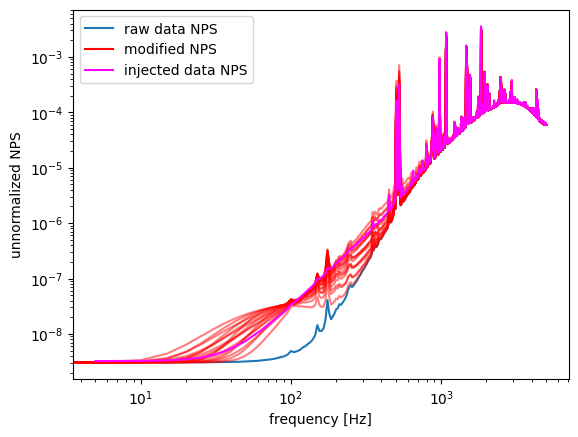

3 1
4.2766658195556086e-05


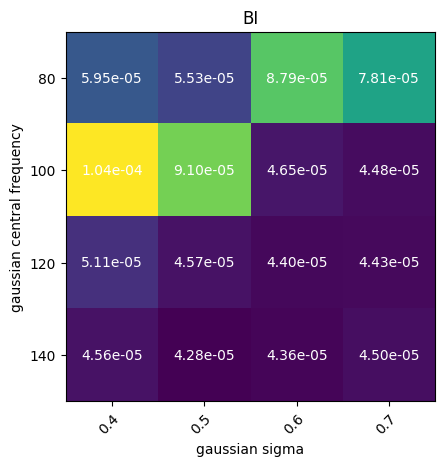

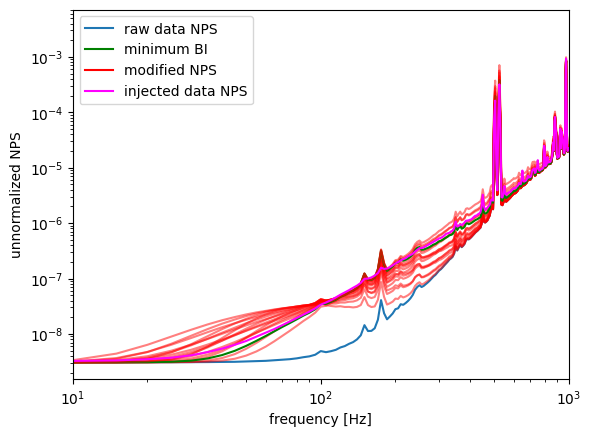

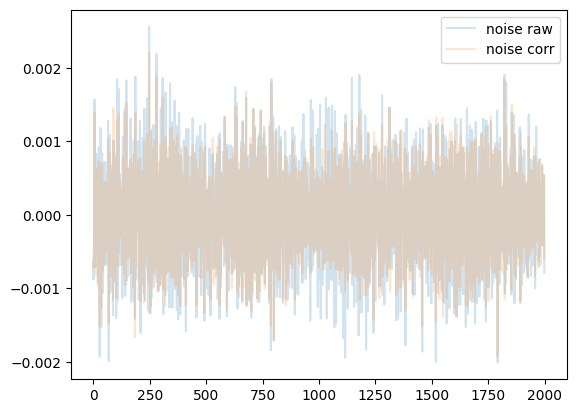

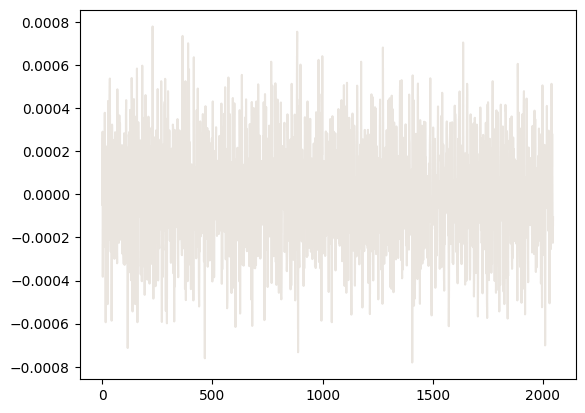

3


True

25_01_20


'/feynman/work/projets/cupid/scratch/mpageot/data/trainings/25_01_15_AutoencoderSkipLay'